## Lab - EDA Bivariate Analysis

## Import Libraries

In [14]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

## Load Data

In [15]:
df = pd.read_csv("data/amz_uk_price_prediction_dataset 2.csv")

## Initial Exploration

In [16]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [17]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               str    
 2   title              str    
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 151.5 MB


In [18]:
df.describe()

,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [19]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='str')

### Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

#### 1. Crosstab Analysis

In [20]:
# Crosstab between category and best seller status

category_bestseller = pd.crosstab(
    df["category"],
    df["isBestSeller"]
)

category_bestseller

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [21]:
category_bestseller_prop = pd.crosstab(
    df["category"],
    df["isBestSeller"],
    normalize="index"
)

category_bestseller_prop

isBestSeller,False,True
category,,
3D Printers,0.995968,0.004032
3D Printing & Scanning,0.999508,0.000492
Abrasive & Finishing Products,0.980000,0.020000
Action Cameras,0.999411,0.000589
Adapters,0.988189,0.011811
...,...,...
Wind Instruments,0.972000,0.028000
Window Treatments,0.979079,0.020921
Women,0.988015,0.011985


In [22]:
category_bestseller_prop = (
    category_bestseller_prop
    .sort_values(by=True, ascending=False)
)

category_bestseller_prop.head(10)

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
"Billiard, Snooker & Pool",0.967871,0.032129
Pet Supplies,0.969800,0.030200
Home Brewing & Wine Making,0.971545,0.028455
Wind Instruments,0.972000,0.028000


**Interpretation:**

Best seller prevalence varies across product categories. Grocery, Smart Home Security & Lighting, and Health & Personal Care show the highest best seller proportions among the categories in the dataset, each at approximately 5.8%.

However, these percentages should be interpreted together with category size. Categories with relatively few products may produce less stable proportions than categories with a large number of listings.

#### 2. Statistical Tests

In [25]:
from scipy.stats import chi2_contingency

In [32]:
chi2, p, dof, expected = chi2_contingency(category_bestseller)

print(f"Chi-square statistic: {chi2:.2f}")
print("P-value: < 0.001" if p < 0.001 else f"P-value: {p:.3f}")
print(f"Degrees of freedom: {dof}")

Chi-square statistic: 36540.20
P-value: < 0.001
Degrees of freedom: 295


**Interpretation:**

The Chi-square test produced a p-value below 0.05, so the null hypothesis of independence is rejected. This indicates that product category and best-seller status are statistically associated.

In [27]:
n = category_bestseller.to_numpy().sum()

min_dimension = min(category_bestseller.shape) - 1

cramers_v = np.sqrt(
    chi2 / (n * min_dimension)
)

print(f"Cramér's V: {cramers_v:.3f}")

Cramér's V: 0.122


Cramér's V is 0.122, indicating a weak association between product category and best seller status.

Therefore, although best seller prevalence differs significantly across categories, category has only a limited association with best seller status in this dataset. Other variables, such as price, ratings, brand, product visibility, and review volume, may also be relevant, but their contribution is not tested in this section.

### Chi-square Test vs. Cramér's V

The Chi-square test evaluates whether two categorical variables are statistically independent.

A p-value below 0.05 provides evidence of an association, but it does not measure the strength or business importance of that relationship.

Cramér's V measures the strength of association between categorical variables on a scale from 0 to 1.

In this analysis:

* The Chi-square test shows a statistically significant association.
* Cramér's V shows that the association is weak.
* Statistical significance should therefore not be confused with a strong practical relationship.

#### 3. Visualizations

To maintain readability, the visualization is limited to the 20 categories with the highest number of products.

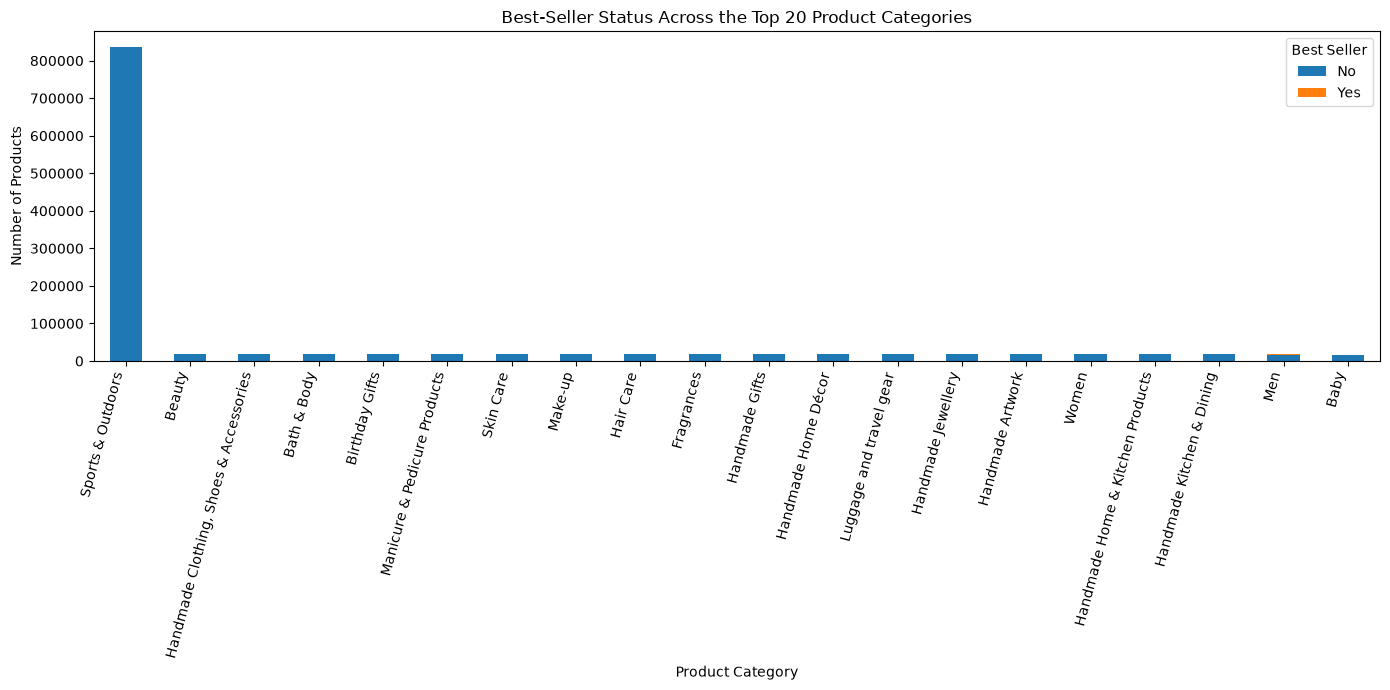

In [29]:
# Select the 20 categories with the largest number of products
top_20_categories = df["category"].value_counts().head(20).index

# Filter the crosstab to the top 20 categories
top_20_crosstab = category_bestseller.loc[top_20_categories]

# Create a stacked bar chart
top_20_crosstab.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Best-Seller Status Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=75, ha="right")
plt.legend(
    title="Best Seller",
    labels=["No", "Yes"]
)
plt.tight_layout()
plt.show()

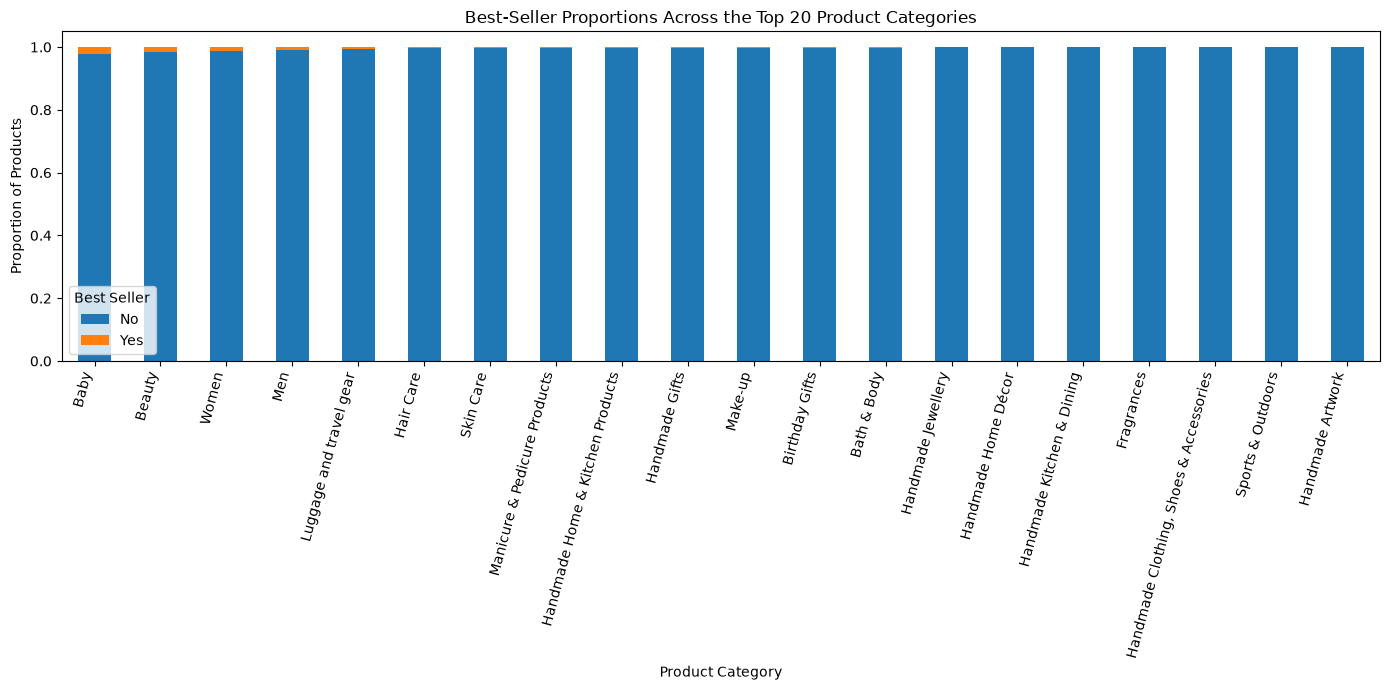

In [30]:
# Calculate proportions for the top 20 categories
top_20_proportions = (
    category_bestseller
    .loc[top_20_categories]
    .div(category_bestseller.loc[top_20_categories].sum(axis=1), axis=0)
)

# Sort by best-seller proportion
top_20_proportions = top_20_proportions.sort_values(
    by=True,
    ascending=False
)

# Create a 100% stacked bar chart
top_20_proportions.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7)
)

plt.title("Best-Seller Proportions Across the Top 20 Product Categories")
plt.xlabel("Product Category")
plt.ylabel("Proportion of Products")
plt.xticks(rotation=75, ha="right")
plt.legend(
    title="Best Seller",
    labels=["No", "Yes"]
)
plt.tight_layout()
plt.show()

**Business Insight:**

The stacked bar chart confirms that non-best sellers represent the majority of products across the largest categories. Nevertheless, the share of best sellers varies between categories, supporting the statistically significant association identified by the Chi-square test.

The proportional chart provides a more meaningful comparison than raw counts because category sizes differ substantially. However, the differences remain relatively limited overall, which is consistent with the weak Cramér's V value of 0.122.

### Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

#### 0. Preliminary Step: Remove outliers in product prices.

In [33]:
# Calculate Q1, Q3 and IQR

Q1 = df["price"].quantile(0.25)
Q3 = df["price"].quantile(0.75)

IQR = Q3 - Q1

In [34]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

In [35]:
df_no_outliers = df[
    (df["price"] >= lower_bound) &
    (df["price"] <= upper_bound)
]

df_no_outliers.shape

(2115963, 9)

In [36]:
print(f"Original dataset: {df.shape}")
print(f"Without outliers: {df_no_outliers.shape}")
print(f"Rows removed: {df.shape[0]-df_no_outliers.shape[0]}")

Original dataset: (2443651, 9)
Without outliers: (2115963, 9)
Rows removed: 327688


Extreme product prices were removed using the IQR method before conducting the remaining analyses. Removing outliers reduces the influence of unusually expensive or inexpensive products and provides a more representative comparison of price distributions across categories.

#### 1. Violin Plots

In [37]:
top20_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(20)
    .index
)

In [38]:
top20_df = df_no_outliers[
    df_no_outliers["category"].isin(top20_categories)
]

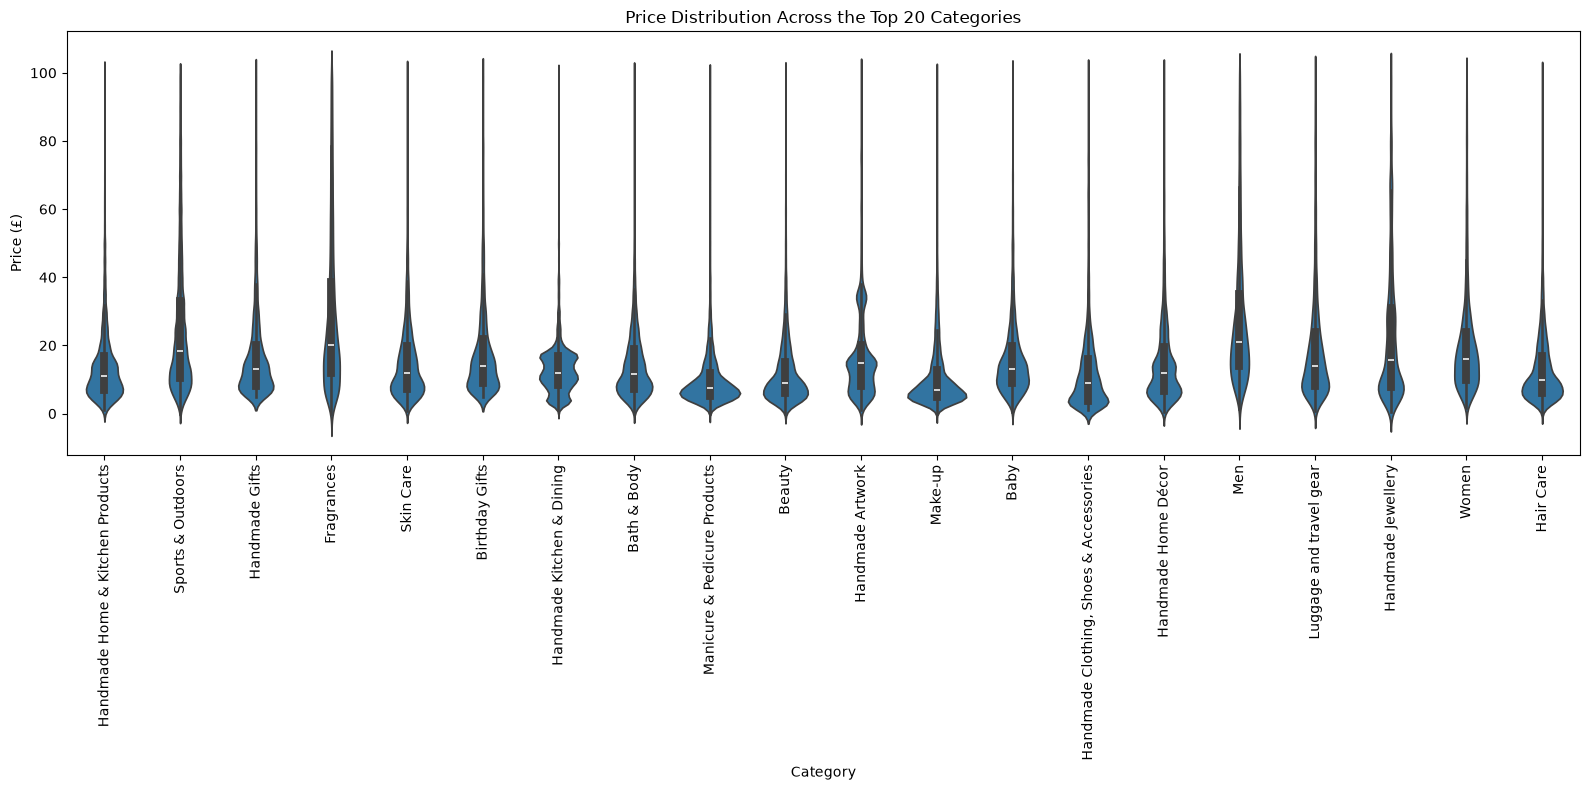

In [39]:
plt.figure(figsize=(16,8))

sns.violinplot(
    data=top20_df,
    x="category",
    y="price"
)

plt.xticks(rotation=90)
plt.title("Price Distribution Across the Top 20 Categories")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.tight_layout()

plt.show()

In [40]:
category_medians = (
    df_no_outliers
    .groupby("category")["price"]
    .median()
    .sort_values(ascending=False)
)

category_medians.head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

The violin plot shows that price distributions differ substantially across categories. Some categories have relatively narrow price ranges, while others exhibit much greater variability.

Among all categories, **Desktop PCs** have the highest median price (£74.00), followed by **Boxing Shoes** (£69.79) and **Tablets** (£69.00). These categories generally contain higher-priced products than the rest of the dataset.

#### 2. Bar Charts

In [41]:
average_price = (
    df_no_outliers
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

average_price.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

In [42]:
top10_categories = (
    df_no_outliers["category"]
    .value_counts()
    .head(10)
    .index
)

top10_average_price = (
    df_no_outliers[
        df_no_outliers["category"].isin(top10_categories)
    ]
    .groupby("category")["price"]
    .mean()
    .sort_values(ascending=False)
)

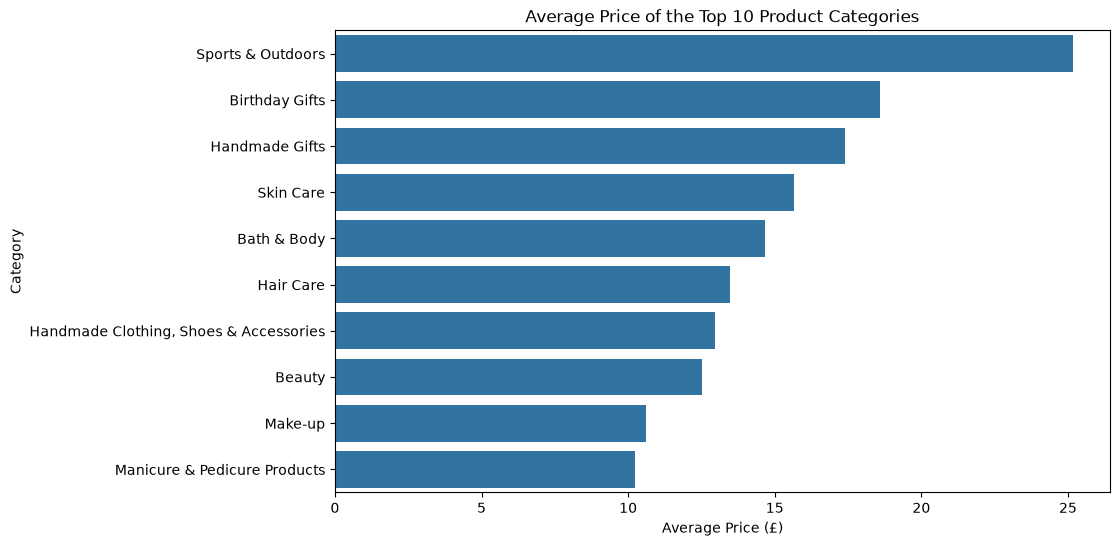

In [43]:
plt.figure(figsize=(10,6))

sns.barplot(
    x=top10_average_price.values,
    y=top10_average_price.index
)

plt.title("Average Price of the Top 10 Product Categories")
plt.xlabel("Average Price (£)")
plt.ylabel("Category")

plt.show()

In [44]:
average_price.head(10)

category
Motherboards         68.772432
Boxing Shoes         67.417803
Desktop PCs          66.915562
Tablets              66.552971
Graphics Cards       65.103509
Digital Frames       60.745129
Streaming Clients    60.241803
Hockey Shoes         60.094796
Computer Cases       58.339884
Skiing Poles         57.867770
Name: price, dtype: float64

Considering all product categories after removing price outliers, **Motherboards** have the highest average price at approximately **£68.77**.

This differs from the median price ranking, where **Desktop PCs** ranked first. The difference shows why both mean and median are useful. The mean is more sensitive to relatively high priced observations, while the median reflects the middle value of the distribution.

Motherboards, Boxing Shoes, Desktop PCs, Tablets, and Graphics Cards form the highest average price group in the filtered dataset. This suggests that technology hardware and selected specialist sports categories generally command higher prices than many other product categories.

### Mean vs. Median Across Categories

The mean and median can produce different category rankings because they respond differently to skewed distributions.

The mean uses every observation and is influenced by relatively high or low values.

The median identifies the middle observation and is more resistant to extreme values.

In this dataset:

* Desktop PCs have the highest median price.
* Motherboards have the highest average price.

This indicates that the price distributions within these categories are not identical and may differ in skewness or spread.

### 3. Box Plots

In [45]:
# Keep only products with a recorded customer rating

df_rated = df_no_outliers[
    df_no_outliers["stars"] > 0
].copy()

print(f"Products after price outlier removal: {df_no_outliers.shape[0]}")
print(f"Products with a recorded rating: {df_rated.shape[0]}")

Products after price outlier removal: 2115963
Products with a recorded rating: 1114343


In [46]:
top10_rating_categories = (
    df_rated["category"]
    .value_counts()
    .head(10)
    .index
)

top10_rating_df = df_rated[
    df_rated["category"].isin(top10_rating_categories)
]

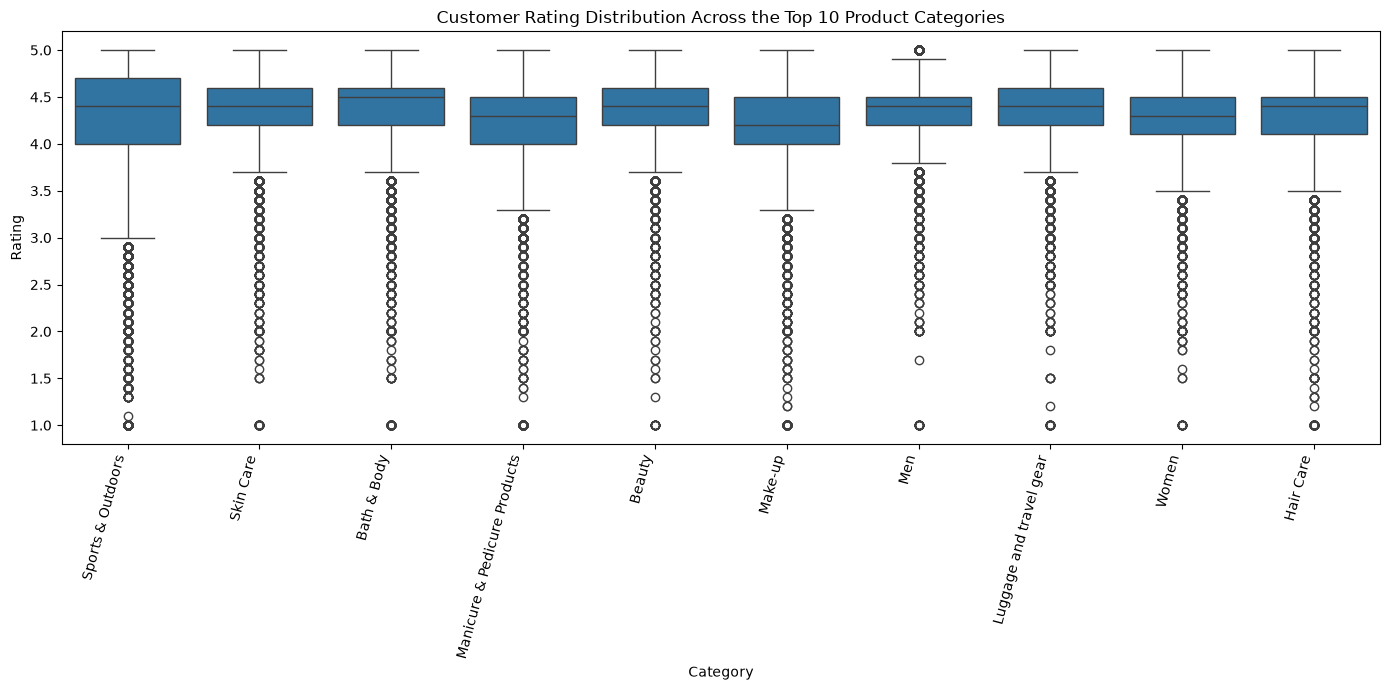

In [47]:
plt.figure(figsize=(14, 7))

sns.boxplot(
    data=top10_rating_df,
    x="category",
    y="stars"
)

plt.title("Customer Rating Distribution Across the Top 10 Product Categories")
plt.xlabel("Category")
plt.ylabel("Rating")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

In [48]:
category_median_ratings = (
    df_rated
    .groupby("category")["stars"]
    .median()
    .sort_values(ascending=False)
)

category_median_ratings.head(10)

category
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Artwork                          5.0
Handmade Kitchen & Dining                 4.9
Handmade Clothing, Shoes & Accessories    4.9
Handmade Gifts                            4.8
Birthday Gifts                            4.8
Handmade Home Décor                       4.8
Handmade Home & Kitchen Products          4.7
Gifts for Him                             4.7
Name: stars, dtype: float64

In [49]:
rating_summary = (
    df_rated
    .groupby("category")
    .agg(
        median_rating=("stars", "median"),
        rated_product_count=("stars", "count")
    )
    .sort_values(
        by=["median_rating", "rated_product_count"],
        ascending=[False, False]
    )
)

rating_summary.head(10)

,median_rating,rated_product_count
category,,
Handmade Artwork,5.0,4155
Handmade Baby Products,5.0,1235
Made in Italy Handmade,5.0,303
"Handmade Clothing, Shoes & Accessories",4.9,4429
Handmade Kitchen & Dining,4.9,2739
Handmade Gifts,4.8,9871
Handmade Home Décor,4.8,7966
Birthday Gifts,4.8,7875
Handmade Home & Kitchen Products,4.7,10722


Several handmade product categories have the highest median customer ratings. **Handmade Artwork**, **Handmade Baby Products**, and **Made in Italy Handmade** all achieve a median rating of **5.0**.

These results suggest high customer satisfaction within handmade product categories. In particular, **Handmade Artwork** stands out because it maintains a perfect median rating across **4,155 rated products**, making this result more robust than categories with relatively few rated products.

Overall, the box plot shows that ratings are concentrated between 4 and 5 stars across most categories, indicating that the majority of rated Amazon products receive positive customer feedback.

### Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

### 1. Correlation Coefficients

In [50]:
 # Calculate the Pearson correlation between price and customer rating

correlation = df_rated["price"].corr(df_rated["stars"])

print(f"Correlation coefficient: {correlation:.3f}")

Correlation coefficient: 0.007


The Pearson correlation coefficient between product price and customer rating is **0.007**, indicating an almost nonexistent linear relationship.

This suggests that more expensive products do not consistently receive higher customer ratings. Product quality, customer expectations, brand reputation, and other factors are likely to have a greater influence on customer ratings than price alone.

### 2. Visualizations

In [51]:
# Draw a random sample for visualization

sample_df = df_rated.sample(
    n=10000,
    random_state=42
)

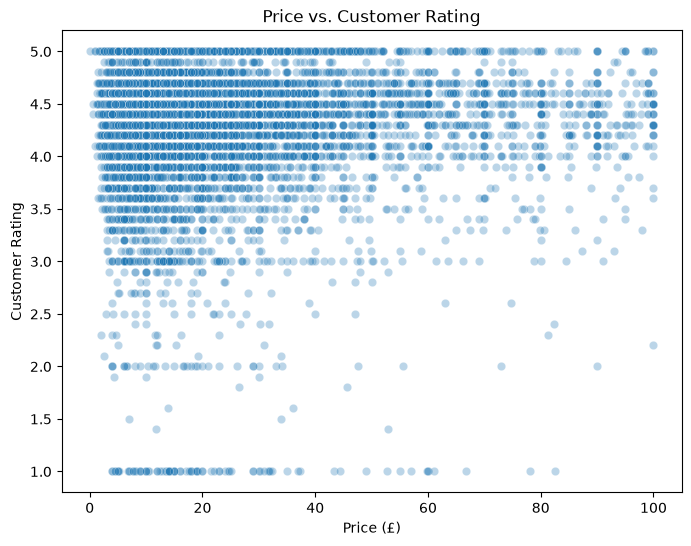

In [52]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=sample_df,
    x="price",
    y="stars",
    alpha=0.3
)

plt.title("Price vs. Customer Rating")
plt.xlabel("Price (£)")
plt.ylabel("Customer Rating")

plt.show()

The scatter plot does not reveal a clear relationship between product price and customer rating. Highly rated products are found across both low and high price ranges, while lower ratings also occur at different price levels.

This visual pattern is consistent with the Pearson correlation coefficient of **0.007**, confirming that price alone is not a meaningful predictor of customer ratings.

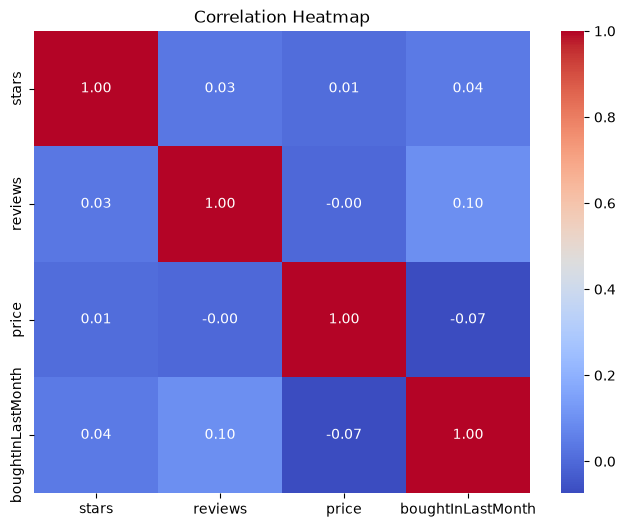

In [53]:
plt.figure(figsize=(8,6))

correlation_matrix = df_rated[
    ["stars", "reviews", "price", "boughtInLastMonth"]
].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

The correlation heatmap shows that all numerical variables have weak pairwise correlations.

Customer ratings have almost no linear relationship with product price (**0.01**) or the number of reviews (**0.03**).

The strongest observed relationship is between the number of reviews and products bought in the last month (**0.10**), but this association is still weak.

Overall, no strong linear relationships are present among the numerical variables in this dataset.